![header](dc_map_header_center.png)

## Deliverable 2: Exploratory Visualization Direction

This deliverable explores whether crash concentrations in Washington, DC are associated with roadway network conditions and whether these patterns are more concentrated in census tracts with higher Black and Hispanic population shares.

The analysis focuses on four questions:

1. How are crashes distributed across census tracts?
2. Do crash concentrations remain high after adjusting for tract area, population, or roadway length?
3. Are roadway network features, such as road length, traffic signal density, intersection density, AADT, bike lanes, sidewalks, and roadway width, associated with higher crash concentration?
4. Do tracts with higher Black and Hispanic population shares also show higher crash concentration or higher roadway-related exposure?

### Exploratory Visualizations

- Crash count distribution
- Crash density by census tract
- Crash patterns by month and year
- Roadway features vs crash count / crash density
- Traffic signal density vs crash concentration
- Intersection density vs crash concentration
- Black population share vs crash density
- Hispanic population share vs crash density
- Crash density by demographic quartile
- Combined roadway exposure and demographic comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import geopandas as gpd
from shapely.geometry import Point

In [2]:
auto_claims_dc = pd.read_csv("../../../Data/auto_claims_dc.csv")
auto_claims_dc.head(3)

,GEOID,year,month,crash_count,speeding_count,total_vehicles,fatal_driver,fatal_pedestrian,fatal_bicyclist,major_inj_driver,...,lpi_ct,ntor_ct,all_ped_phase_ct,bike_phase_ct,queue_jump_ct,tsp_ct,hawk_ct,aps_installed_ct,aps_planned_ct,ped_signal_mode_ct
0,11001000101,2019.0,1.0,2,0,4,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,11001000101,2019.0,3.0,2,0,4,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,11001000101,2019.0,4.0,3,0,6,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
auto_claims_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11811 entries, 0 to 11810
Data columns (total 100 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   GEOID                          11811 non-null  int64  
 1   year                           11811 non-null  float64
 2   month                          11811 non-null  float64
 3   crash_count                    11811 non-null  int64  
 4   speeding_count                 11811 non-null  int64  
 5   total_vehicles                 11811 non-null  int64  
 6   fatal_driver                   11811 non-null  int64  
 7   fatal_pedestrian               11811 non-null  int64  
 8   fatal_bicyclist                11811 non-null  int64  
 9   major_inj_driver               11811 non-null  int64  
 10  major_inj_ped                  11811 non-null  int64  
 11  major_inj_bike                 11811 non-null  int64  
 12  weekend_crash                  11811 non-null

## Limitations

### Crash Data Coverage

Crash data were obtained from the DDOT “Crashes in DC” dataset, which is derived from the Metropolitan Police Department’s (MPD) COBALT crash reporting system and enhanced through DDOT roadway block geolocation procedures.

Crashes with incomplete, inaccurate, or missing location information may not appear in the published dataset. As a result, the dataset may not fully represent the complete universe of crash events occurring in Washington, DC.

---

### Exposure Measurement Limitations

This project does not include direct transportation exposure variables such as:

- traffic volume
- vehicle miles traveled (VMT)
- pedestrian counts
- bicycle traffic counts

As a result, areas with higher crash counts or crash density may partially reflect higher traffic exposure rather than roadway risk alone.

---

### Static Roadway Feature Limitations

Many roadway variables in the roadway block dataset represent relatively static, modeled, or estimated roadway characteristics rather than annually updated measurements.

Examples include:

- roadway width
- lane width
- roadway classifications
- certain traffic-related estimates

Because these variables are largely static over time, the analysis is limited in its ability to perform before-after policy evaluation or strong causal inference regarding roadway changes and crash outcomes.

---

### COVID-19 Structural Break

Crash patterns during 2020 showed substantial disruption relative to surrounding years, likely reflecting major behavioral and mobility changes associated with the COVID-19 pandemic.

This structural break may weaken standard assumptions regarding:

- normal traffic seasonality
- long-term temporal stability
- year-to-year comparability

---

### Interpretation Limitations

This project evaluates relationships, associations, spatial correlations, and risk concentration patterns between roadway characteristics, demographic variables, and crash outcomes.

The analysis does not establish direct causation between roadway features and crashes.

### Ask
How are roadway characteristics spatially associated with crash concentration?

### Exploratory Visualizations

- Crash density by census tract
- Crash patterns by month and year
- Roadway features vs crash count / crash density
- Traffic signal density vs crash concentration
- Intersection density vs crash concentration
- Black population share vs crash density
- Hispanic population share vs crash density
- Crash density by demographic quartile
- Combined roadway exposure and demographic comparison

#### 1.1 Crash count distribution

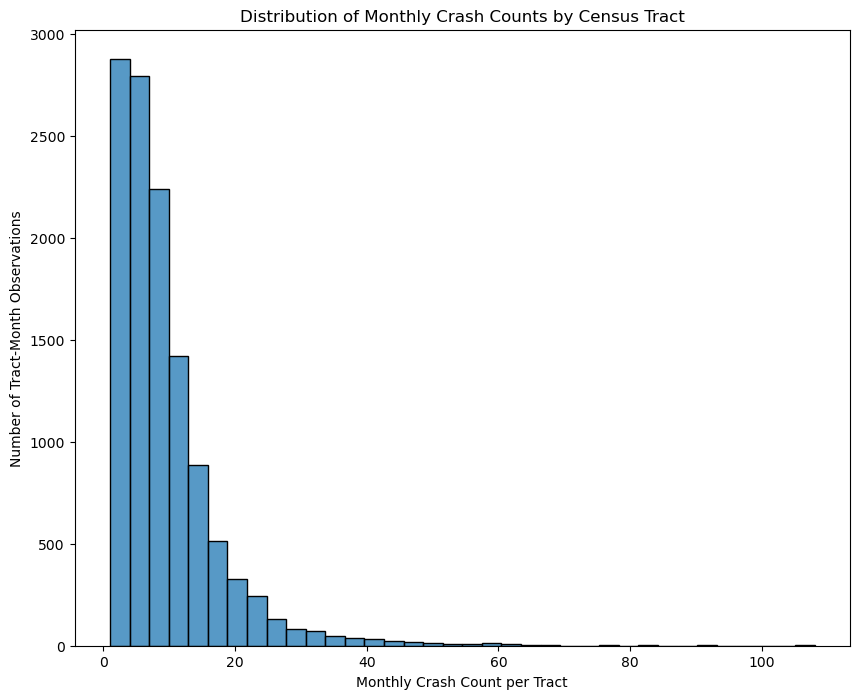

In [4]:
plt.figure(figsize=(10, 8))

sns.histplot(
    data=auto_claims_dc,
    x="crash_count",
    binwidth=3
)

plt.title("Distribution of Monthly Crash Counts by Census Tract")
plt.xlabel("Monthly Crash Count per Tract")
plt.ylabel("Number of Tract-Month Observations")

plt.show()

#### 1.2 Crash patterns by month and year

In [5]:
crashes_patterns = (
    auto_claims_dc
    .groupby(['year', 'month'], as_index=False)
    .agg(total_crashes=('crash_count', 'sum'))
)

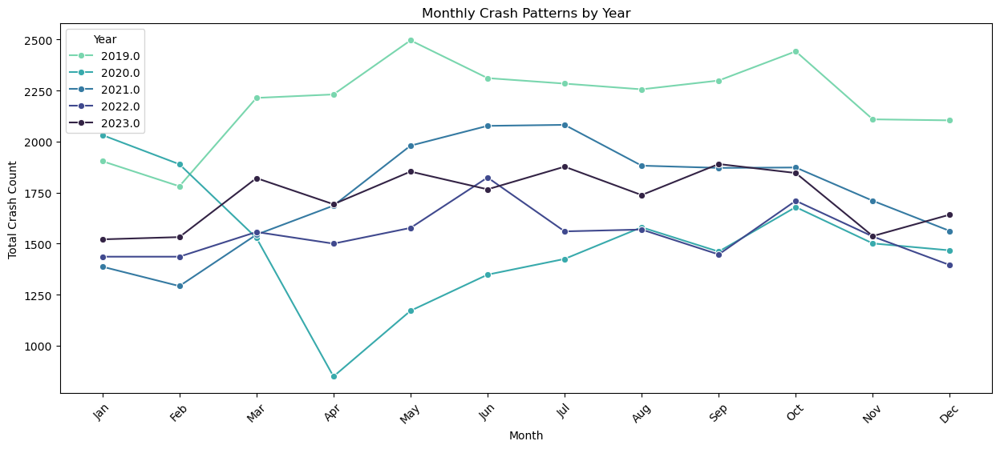

In [6]:
plt.figure(figsize=(15, 6))

palette = sns.color_palette("mako_r", 5)

sns.lineplot(
    data=crashes_patterns,
    x="month",
    y="total_crashes",
    hue="year",
    marker="o",
    color="0.7",
    palette=palette
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.title("Monthly Crash Patterns by Year")
plt.xlabel("Month")
plt.ylabel("Total Crash Count")
plt.xticks(range(1, 13), month_labels, rotation=45)
plt.legend(title="Year")
plt.show()

- seasonality
- year-to-year difference
- COVID dip
- summer peak

#### 1.3 Long-term temporal trend

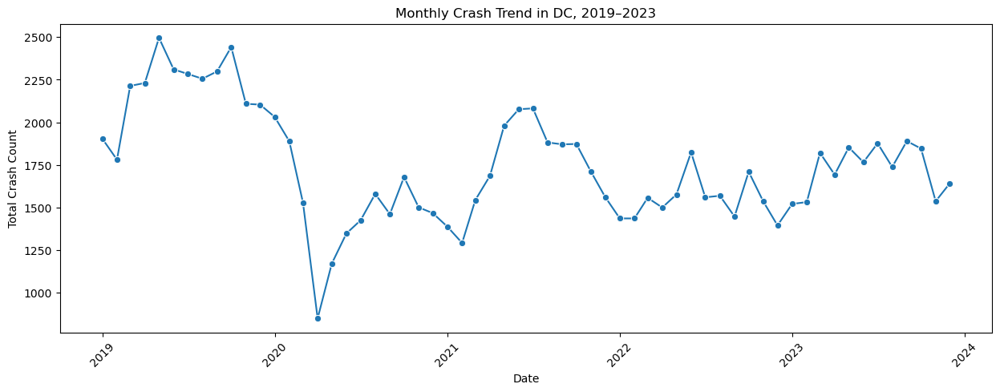

In [7]:
crashes_patterns["date"] = pd.to_datetime(
    crashes_patterns[["year", "month"]].assign(day=1)
)

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=crashes_patterns,
    x="date",
    y="total_crashes",
    marker="o"
)

plt.title("Monthly Crash Trend in DC, 2019–2023")
plt.xlabel("Date")
plt.ylabel("Total Crash Count")
plt.xticks(rotation=45)
plt.show()

- COVID crash collapse
- recovery
- stabilization afterward

#### 1.4 Census tract-level demographic composition choropleth map

Do census tracts with higher crash density also tend to have different demographic compositions? 

For example, this analysis examines whether census tracts with higher Black population share also tend to have higher crash density. This should be interpreted as a tract-level spatial association, not as causal evidence and not as an analysis of the race or ethnicity of individuals involved in crashes.

***This project identifies spatial crash risk concentration across Washington, DC and examines how crash density is associated with roadway characteristics and tract-level demographic composition.***

This project should be interpreted as an exploratory spatial risk and equity analysis. It examines whether crash density is associated with roadway environment characteristics and tract-level demographic composition across Washington, DC census tracts.

The analysis does not establish causality and does not identify the race or ethnicity of individuals involved in crashes. Instead, it helps identify spatial patterns, risk concentrations, and areas that may require further investigation or policy attention.

In [8]:
# ======================================================
# 2019–2023 ACS Demographics - Spatial Preparation
# ======================================================

acs_demographics = gpd.read_file(
    "../../../Data/ACS_5-Year_Demographic_Characteristics_of_DC_Census_Tracts/ACS_5-Year_Demographic_Characteristics_of_DC_Census_Tracts.shp"
)

# 1. Convert CRS first
acs_demo = acs_demographics.to_crs("EPSG:4326").copy()

In [9]:
import geopandas as gpd

# ============================================================
# Make sure GEOID types match
# ============================================================
acs_demo["GEOID"] = acs_demo["GEOID"].astype(str)
auto_claims_dc["GEOID"] = auto_claims_dc["GEOID"].astype(str)

# ============================================================
# Prepare tract-level demographic data
# ============================================================

race_cols = [
    "white_alone_share",
    "black_alone_share",
    "asian_alone_share",
    "hispanic_share",
    "two_or_more_races_share",
    "other_race_share"
]

tract_demo = (
    auto_claims_dc[["GEOID"] + race_cols]
    .drop_duplicates(subset="GEOID")
    .copy()
)

# Merge geometry back by GEOID
map_demo = acs_demo[["GEOID", "geometry"]].merge(
    tract_demo,
    on="GEOID",
    how="left"
)

map_demo = gpd.GeoDataFrame(
    map_demo,
    geometry="geometry",
    crs="EPSG:4326"
)

In [10]:
map_demo.head(3)

,GEOID,geometry,white_alone_share,black_alone_share,asian_alone_share,hispanic_share,two_or_more_races_share,other_race_share
0,11001005302,"POLYGON ((-77.04167 38.91154, -77.04136 38.911...",0.766392,0.033765,0.096977,0.146447,0.063212,0.039654
1,11001004402,"POLYGON ((-77.03195 38.9163, -77.03195 38.9163...",0.633640,0.139033,0.060328,0.060328,0.131442,0.035557
2,11001010602,"POLYGON ((-77.00444 38.90252, -77.00415 38.903...",0.541478,0.304168,0.058605,0.061494,0.072637,0.023112


In [11]:
map_demo.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 206 entries, 0 to 205
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   GEOID                    206 non-null    object  
 1   geometry                 206 non-null    geometry
 2   white_alone_share        206 non-null    float64 
 3   black_alone_share        206 non-null    float64 
 4   asian_alone_share        206 non-null    float64 
 5   hispanic_share           206 non-null    float64 
 6   two_or_more_races_share  206 non-null    float64 
 7   other_race_share         206 non-null    float64 
dtypes: float64(6), geometry(1), object(1)
memory usage: 13.0+ KB


In [12]:
import folium

# Convert shares from 0–1 to 0–100 for easier map interpretation
for col in race_cols:
    map_demo[col + "_pct"] = map_demo[col] * 100

race_layers = {
    "White Alone Share (%)": "white_alone_share_pct",
    "Black Alone Share (%)": "black_alone_share_pct",
    "Asian Alone Share (%)": "asian_alone_share_pct",
    "Hispanic or Latino Share (%)": "hispanic_share_pct",
    "Two or More Races Share (%)": "two_or_more_races_share_pct",
    "Other Race Share (%)": "other_race_share_pct"
}

m = folium.Map(
    location=[38.9072, -77.0369],
    zoom_start=11,
    tiles="cartodbpositron"
)

for layer_name, col in race_layers.items():
    folium.Choropleth(
        geo_data=map_demo,
        data=map_demo,
        columns=["GEOID", col],
        key_on="feature.properties.GEOID",
        fill_color="YlOrRd",
        fill_opacity=0.7,
        line_opacity=0.2,
        nan_fill_color="lightgray",
        legend_name=layer_name,
        name=layer_name,
        show=(layer_name == "Black Alone Share (%)")
    ).add_to(m)

# Add transparent GeoJson/tract_polygon layer for tooltip
tooltip_fields = ["GEOID"] + list(race_layers.values())

tooltip_aliases = [
    "Census Tract:",
    "White Alone Share (%)",
    "Black Alone Share (%)",
    "Asian Alone Share (%)",
    "Hispanic or Latino Share (%)",
    "Two or More Races Share (%)",
    "Other Race Share (%)"
]

folium.GeoJson(
    map_demo,
    name="Tract Demographic Tooltip",
    style_function=lambda feature: {
        "fillColor":"transparent",
        "color":"black",
        "weight":0.3,
        "fill0pacity":0
    },
    tooltip=folium.GeoJsonTooltip(
        fields=tooltip_fields,
        aliases=tooltip_aliases,
        localize=True,
        sticky=True
    )
).add_to(m)

folium.LayerControl(collapsed=False).add_to(m)

m

Darker census tracts indicate a higher Black population share. This map shows tract-level demographic composition, not crash counts or the race of people involved in crashes.

#### 1.5 Crash Density Choropleth Map

Examine whether areas with higher crash density show spatial overlap/association with certain tract-level demographic concentration patterns.

This interactive choropleth map shows tract-level demographic composition across Washington, DC. Each layer represents the population share of one demographic group within each census tract.

Darker colors indicate a higher population share for the selected demographic group. Users should view one demographic layer at a time because multiple choropleth layers overlap on the same census tract polygons and may produce misleading colors.

The tooltip displays the full demographic composition of each tract for reference. This map does not show crash counts, crash density, or the race/ethnicity of individuals involved in crashes. It is used as contextual spatial information to compare with crash density and roadway environment maps.

Crash density was calculated as:
$$
\text{Crash Density} = \frac{\text{Total Crashes in Census Tract}}{\text{Tract Area in km}^2}
$$

In [13]:
# ============================================================
# Crash Density by Census Tract
# ============================================================

# Overall 5-year average map
crash_density_df = (
    auto_claims_dc
    .groupby("GEOID", as_index=False)
    .agg(
        total_crashes=("crash_count", "sum"),
        area_km2=("area_km2", "first")
    )
)

crash_density_df["avg_annual_crash_density"] = (
    crash_density_df["total_crashes"] / 5 / crash_density_df["area_km2"]
)
crash_density_df.head(3)

,GEOID,total_crashes,area_km2,avg_annual_crash_density
0,11001000101,104,0.199776,104.116611
1,11001000102,782,1.706484,91.650434
2,11001000201,79,0.505004,31.286881


In [14]:
# ============================================================
# Make sure GEOID types match
# ============================================================
acs_demo["GEOID"] = acs_demo["GEOID"].astype(str)
crash_density_df["GEOID"] = crash_density_df["GEOID"].astype(str)

# ============================================================
# Merge crash density data with tract geometry
# ============================================================
map_crash_density = acs_demo[["GEOID", "geometry"]].merge(
    crash_density_df,
    on="GEOID",
    how="left"
)

map_crash_density = gpd.GeoDataFrame(
    map_crash_density,
    geometry="geometry",
    crs="EPSG:4326"
)

map_crash_density.head(3)

,GEOID,geometry,total_crashes,area_km2,avg_annual_crash_density
0,11001005302,"POLYGON ((-77.04167 38.91154, -77.04136 38.911...",118,0.117635,200.620564
1,11001004402,"POLYGON ((-77.03195 38.9163, -77.03195 38.9163...",887,0.274746,645.687289
2,11001010602,"POLYGON ((-77.00444 38.90252, -77.00415 38.903...",813,0.542512,299.716873


In [15]:
m1 = folium.Map(
    location=[38.9072, -77.0369],
    zoom_start=11,
    tiles="cartodbpositron"
)

folium.Choropleth(
    geo_data=map_crash_density,
    data=map_crash_density,
    columns=["GEOID", "avg_annual_crash_density"],
    key_on="feature.properties.GEOID",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.2,
    nan_fill_color="lightgray",
    legend_name="Average Annual Crash Density (Crashes per km² per year)",
    name="Average Annual Crash Density"
).add_to(m1)

# Add tooltip layer
folium.GeoJson(
    map_crash_density,
    name="Crash Density Tooltip",
    style_function=lambda features: {
        "fillColor":"transparent",
        "color":"black",
        "weight":0.3,
        "fill0pacity":0
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["GEOID", "total_crashes", "area_km2", "avg_annual_crash_density"],
        aliases=[
            "Census Tract:",
            "Total Crashes:",
            "Area (km²):",
            "Avg Annual Crash Density:"
        ],
        localize=True,
        sticky=True
    )
).add_to(m1)

folium.LayerControl(collapsed=False).add_to(m1)

m1

The crash density map and Black population share map show some spatial overlap in parts of eastern and southeastern Washington, DC. However, high crash density is not limited to high Black population share areas and also appears in central areas where roadway activity and traffic exposure may be higher.

This suggests that crash concentration is likely associated with a combination of roadway environment, traffic exposure, and tract-level demographic patterns. The comparison should be interpreted as exploratory spatial association, not causal evidence or an analysis of the race or ethnicity of individuals involved in crashes.

### Spatial Comparison: Crash Density and Black Population Share

- Areas with higher Black population share are mainly concentrated in eastern and southeastern Washington, DC.

- High crash density is not limited to areas with higher Black population share.

- The crash density map also shows higher crash concentrations in downtown and central DC.

- These central crash-density patterns may be related to multiple built-environment and exposure factors, including:
  - roadway complexity
  - intersection density
  - traffic volume / exposure
  - commercial activity
  - population density
  - pedestrian and vehicle activity
  - neighborhood built environment

- Some spatial overlap appears in eastern and southeastern DC, where several tracts with higher Black population share also show relatively higher crash density.

- However, this pattern is not consistent across the entire city.

- Therefore, crash density should not be explained by demographic patterns alone.

- This comparison should be interpreted as an exploratory tract-level spatial association, not as causal evidence or crash victim race analysis.

#### 1.6 Correlation Heatmap

In [16]:
# auto_claims_dc.info()
# ============================================================
# Tract-level master table for EDA and visualization
# One row = one census tract
# ============================================================

# Step 1: Build tract_eda
tract_eda = (
    auto_claims_dc
    .groupby("GEOID", as_index=False)
    .agg(
        # Crash outcomes
        total_crashes=("crash_count", "sum"),
        avg_monthly_crashes=("crash_count", "mean"),
        total_speeding=("speeding_count", "sum"),
        total_vehicles=("total_vehicles", "sum"),
        night_crashes=("night_crash", "sum"),
        weekend_crashes=("weekend_crash", "sum"),
        rush_hour_crashes=("rush_hour_crash", "sum"),

        # Area / population
        area_km2=("area_km2", "first"),
        total_population=("total_population", "first"),

        # Demographics
        white_alone_share=("white_alone_share", "first"),
        black_alone_share=("black_alone_share", "first"),
        asian_alone_share=("asian_alone_share", "first"),
        hispanic_share=("hispanic_share", "first"),
        two_or_more_races_share=("two_or_more_races_share", "first"),
        other_race_share=("other_race_share", "first"),

        # Traffic signal / intersection features
        traffic_ct=("traffic_ct", "first"),
        traffic_intersection_ct=("traffic_intersection_ct", "first"),
        lpi_ct=("lpi_ct", "first"),
        aps_installed_ct=("aps_installed_ct", "first"),

        # Roadway features
        road_segment_count=("road_segment_count", "first"),
        road_total_length_m=("road_total_length_m", "first"),
        mean_aadt=("mean_aadt", "first"),
        mean_iri=("mean_iri", "first"),
        mean_speedlimit_ob=("mean_speedlimit_ob", "first"),
        high_speed_ratio=("high_speed_ratio", "first"),
        bike_lane_ratio=("bike_lane_ratio", "first"),
        sidewalk_ib_ratio=("sidewalk_ib_ratio", "first"),
        sidewalk_ob_ratio=("sidewalk_ob_ratio", "first")
    )
)

In [17]:
# Step 2: Build density / rate variables

# Number of years in dataset
n_years = auto_claims_dc["year"].nunique()

# Road length in km
tract_eda["road_length_km"] = tract_eda["road_total_length_m"] / 1000

# Crash density by land area
tract_eda["crash_density_km2"] = (
    tract_eda["total_crashes"] / tract_eda["area_km2"]
)

# Average annual crash density
tract_eda["avg_annual_crash_density"] = (
    tract_eda["total_crashes"] / n_years / tract_eda["area_km2"]
)

# Crashes per road km
tract_eda["crashes_per_road_km"] = (
    tract_eda["total_crashes"] / tract_eda["road_length_km"]
)

# Crashes per 10,000 population
tract_eda["crashes_per_10k_pop"] = (
    tract_eda["total_crashes"] / tract_eda["total_population"] * 10000
)

# Road density
tract_eda["road_density_km_per_km2"] = (
    tract_eda["road_length_km"] / tract_eda["area_km2"]
)

# Road segment density
tract_eda["road_segment_density_km2"] = (
    tract_eda["road_segment_count"] / tract_eda["area_km2"]
)

# Traffic signal density
tract_eda["signal_density_km2"] = (
    tract_eda["traffic_ct"] / tract_eda["area_km2"]
)

# Traffic intersection density
tract_eda["intersection_density_km2"] = (
    tract_eda["traffic_intersection_ct"] / tract_eda["area_km2"]
)

In [18]:
# Step 3: Tract-level summary for correlation analysis

corr_cols = [
    # Crash outcomes
    "avg_annual_crash_density",
    "crash_density_km2",
    "crashes_per_road_km",
    "crashes_per_10k_pop",

    # Roadway / traffic exposure
    "road_density_km_per_km2",
    "road_segment_density_km2",
    "signal_density_km2",
    "intersection_density_km2",
    "mean_aadt",

    # Road condition / design
    "mean_iri",
    "mean_speedlimit_ob",
    "high_speed_ratio",

    # Demographics
    "black_alone_share",
    "hispanic_share",
    "asian_alone_share",
    "white_alone_share"
]

corr_matrix = tract_eda[corr_cols].corr()

In [19]:
# Simplified tract-lvl summary

corr_cols_simple = [
    "avg_annual_crash_density",

    # Roadway / traffic exposure
    "road_density_km_per_km2",
    "road_segment_density_km2",
    "signal_density_km2",
    "mean_aadt",

    # Road condition / design
    "mean_iri",
    "mean_speedlimit_ob",
    "high_speed_ratio",

    # Demographics
    "black_alone_share",
    "white_alone_share",
    "asian_alone_share",
    "hispanic_share"
]

corr_matrix_simple = tract_eda[corr_cols_simple].corr()

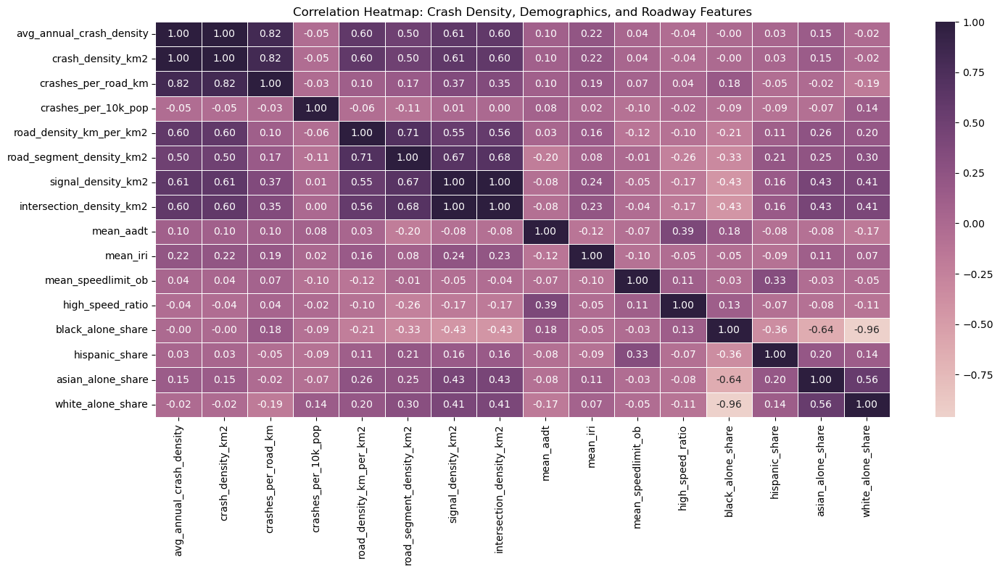

In [20]:
plt.figure(figsize=(15, 8))

sns.heatmap(
    corr_matrix,
    annot=True, # annote every corr vals in each cell
    fmt=".2f",
    cmap=sns.cubehelix_palette(as_cmap=True),
    linewidths=0.5
)

plt.title("Correlation Heatmap: Crash Density, Demographics, and Roadway Features")
plt.tight_layout()

plt.show()

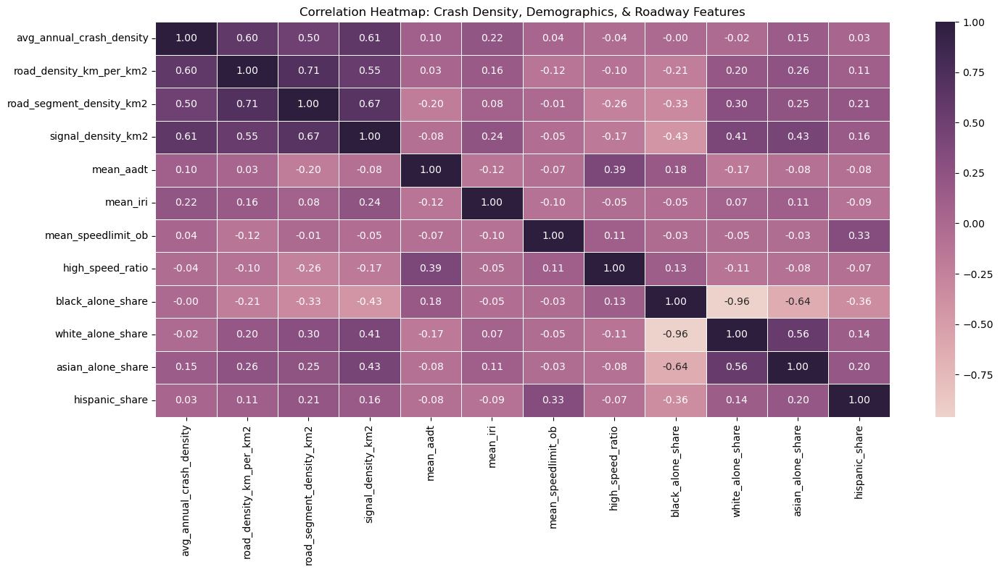

In [21]:
plt.figure(figsize=(15, 8))

sns.heatmap(
    corr_matrix_simple,
    annot=True,
    fmt=".2f",
    cmap=sns.cubehelix_palette(as_cmap=True),
    linewidths=0.5
)

plt.title("Correlation Heatmap: Crash Density, Demographics, & Roadway Features")
plt.tight_layout()

plt.show()


The correlation heatmap does not show a strong linear relationship between average annual crash density and tract-level racial/ethnic population shares.

Not a simple linear relationship: Black share ↑ → crash density ***NOT*** always ↑

crash density = roadway environment + traffic exposure + land use/activity + demographic composition + spatial context

### Correlation Heatmap Interpretation

- The correlation heatmap shows weak linear relationships between average annual crash density and tract-level demographic composition variables.

- Black population share has almost no linear correlation with average annual crash density in this tract-level summary.

- Hispanic, White, and Asian population shares also show only weak correlations with crash density.

- Roadway and traffic-related variables show limited relationships with crash density. Traffic signal count, traffic intersection count, and mean AADT have weak positive correlations with crash density.

- Road segment count shows a moderate negative correlation with crash density, but this should be interpreted cautiously because it may reflect spatial unit effects, roadway segmentation definitions, or area-normalization issues rather than a direct safety relationship.

- Traffic count and traffic intersection count are almost perfectly correlated, suggesting that these variables may be redundant for later modeling.

- Overall, the heatmap suggests that crash density is not strongly explained by any single demographic or roadway variable alone. Crash concentration is likely related to a combination of roadway environment, traffic exposure, built environment, and spatial context.

- These correlations should be interpreted as exploratory associations, not causal evidence.

1. Monthly crash count distribution
2. Monthly crash trend, 2019–2023
3. Crash density map by tract
4. Black / Hispanic population share map
5. Top 15 tracts by crash density
6. Road density vs crash density
7. Signal density vs crash density
8. Intersection density vs crash density
9. Crash density by Black share quartile
10. Crash density by Hispanic share quartile
11. Roadway exposure × demographic quartile heatmap
12. Correlation heatmap

#### 1.7 Top 15 tracts by crash density

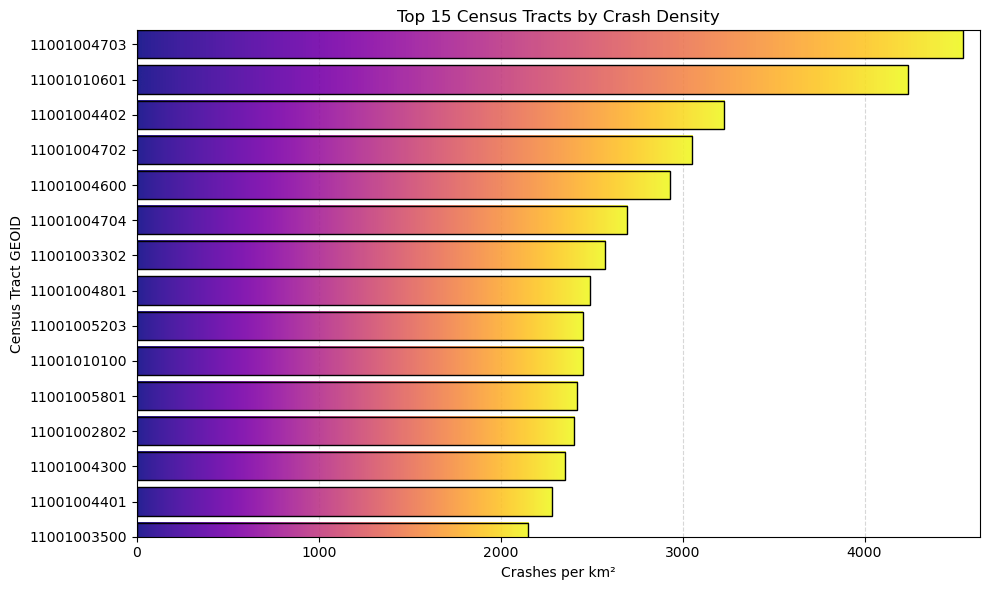

In [22]:
top_crash = tract_eda.sort_values("crash_density_km2", ascending=False).head(15).copy()

top_crash["GEOID"] = top_crash["GEOID"].astype(str)

# Reverse order for matplotlib barh so highest appears at top
top_crash_plot = top_crash.iloc[::-1].copy()

fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(top_crash_plot))

bars = ax.barh(y_pos, top_crash_plot["crash_density_km2"], color="none", edgecolor="black", linewidth=1.0, zorder=3)

gradient = np.linspace(0, 1, 256).reshape(1, -1)

for bar in bars:
    x = bar.get_x()
    y = bar.get_y()
    w = bar.get_width()
    h = bar.get_height()

    ax.imshow(
        gradient,
        extent=[x, x+w, y, y+h],
        cmap="plasma",
        aspect="auto",
        interpolation="bicubic",
        zorder=2,
        alpha=0.9
    )

ax.set_yticks(y_pos)
ax.set_yticklabels(top_crash_plot["GEOID"])

ax.set_title("Top 15 Census Tracts by Crash Density")
ax.set_xlabel("Crashes per km²")
ax.set_ylabel("Census Tract GEOID")

ax.grid(axis="x", linestyle="--", alpha=0.5, zorder=0)
ax.set_xlim(0, top_crash_plot["crash_density_km2"].max() * 1.02)

plt.tight_layout()
plt.show()

Crash concentration is not evenly distributed.

#### 1.8 Road density vs crash density

The main equity analysis focuses on Black and Hispanic population shares, while other race/ethnicity shares are included in correlation and appendix checks.

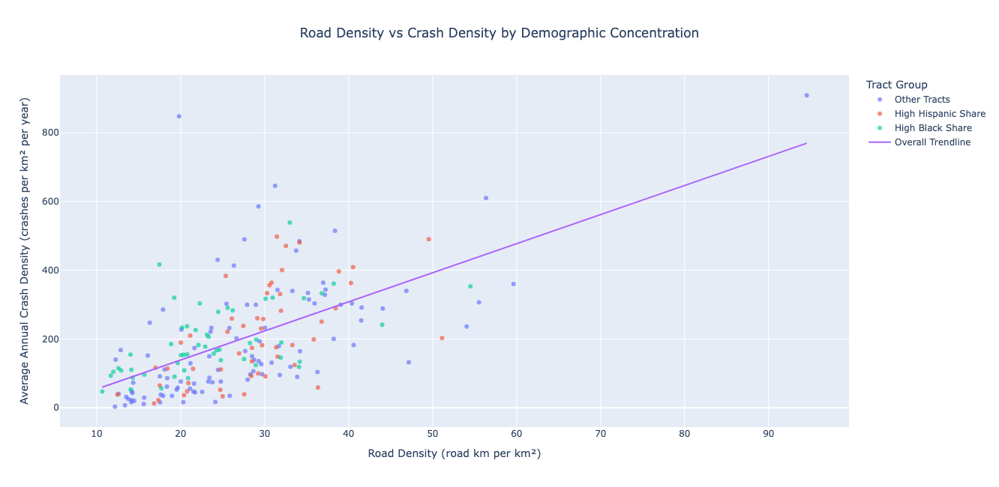

In [23]:
import numpy as np
import plotly.express as px

# Define high-share thresholds
black_cutoff = tract_eda["black_alone_share"].quantile(0.75)
hispanic_cutoff = tract_eda["hispanic_share"].quantile(0.75)

# Create highlight group
tract_eda["demo_highlight"] = np.select(
    [
        (tract_eda["black_alone_share"] >= black_cutoff) & 
        (tract_eda["hispanic_share"] >= hispanic_cutoff),

        tract_eda["black_alone_share"] >= black_cutoff,

        tract_eda["hispanic_share"] >= hispanic_cutoff
    ],
    [
        "High Black + High Hispanic",
        "High Black Share",
        "High Hispanic Share"
    ],
    default="Other Tracts"
)

fig = px.scatter(
    tract_eda,
    x="road_density_km_per_km2",
    y="avg_annual_crash_density",
    color="demo_highlight",
    hover_name="GEOID",
    hover_data=[
        "total_crashes",
        "area_km2",
        "road_density_km_per_km2",
        "avg_annual_crash_density",
        "black_alone_share",
        "white_alone_share",
        "asian_alone_share",
        "hispanic_share",
        "mean_aadt"
    ],
    trendline="ols",
    trendline_scope="overall",
    opacity=0.65,
    title="Road Density vs Crash Density by Demographic Concentration",
    labels={
        "road_density_km_per_km2": "Road Density (road km per km²)",
        "avg_annual_crash_density": "Average Annual Crash Density (crashes per km² per year)",
        "demo_highlight": "Tract Group"
    },
    width=1000,
    height=650
)

fig.update_layout(
    title={
        "text": "Road Density vs Crash Density by Demographic Concentration",
        "x": 0.5,
        "xanchor": "center"
    }
)

fig.show()

The scatterplot suggests a positive association between road density and average annual crash density. Census tracts with denser roadway networks tend to have higher crash density.

Some high Black-share tracts also show elevated crash density, but high crash-density observations are not limited to high Black-share tracts.

High Hispanic-share tracts appear more evenly distributed across the middle range of both road density and crash density, suggesting that the relationship between demographics, roadway exposure, and crash concentration may require additional group-level comparison using boxplots or quartile heatmaps.

sldies:

1. Higher road density is associated with higher average annual crash density across census tracts.

2. Some high Black-share tracts also show elevated crash density, but this pattern is not exclusive to high Black-share tracts.

3. High Hispanic-share tracts appear more evenly distributed across the middle range of both road density and crash density.

#### 1.9 Signal density vs crash density

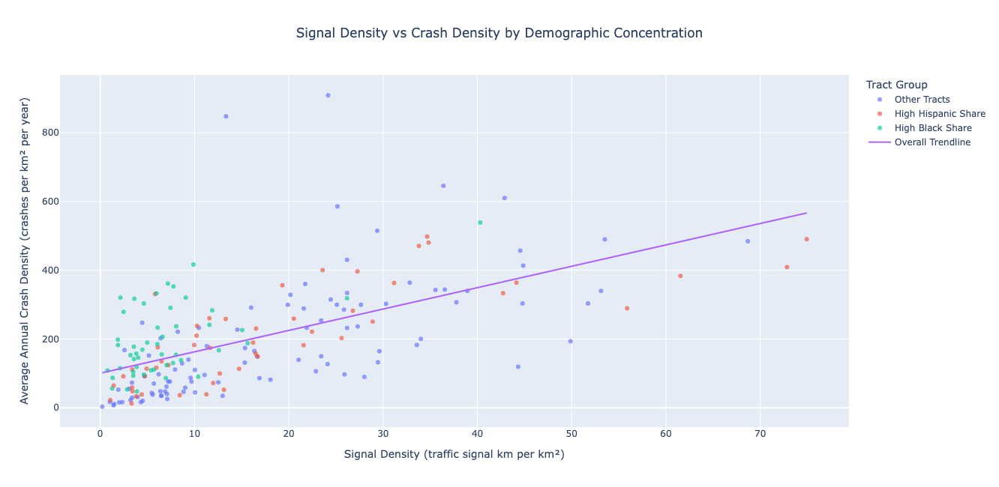

In [24]:

fig = px.scatter(
    tract_eda,
    x="signal_density_km2",
    y="avg_annual_crash_density",
    color="demo_highlight",
    hover_name="GEOID",
    hover_data=[
        "total_crashes",
        "area_km2",
        "road_density_km_per_km2",
        "avg_annual_crash_density",
        "black_alone_share",
        "white_alone_share",
        "asian_alone_share",
        "hispanic_share",
        "mean_aadt"
    ],
    trendline="ols",
    trendline_scope="overall",
    opacity=0.65,
    title="Road Density vs Crash Density by Demographic Concentration",
    labels={
        "signal_density_km2": "Signal Density (traffic signal km per km²)",
        "avg_annual_crash_density": "Average Annual Crash Density (crashes per km² per year)",
        "demo_highlight": "Tract Group"
    },
    width=1000,
    height=650
)

fig.update_layout(
    title={
        "text": "Signal Density vs Crash Density by Demographic Concentration",
        "x": 0.5,
        "xanchor": "center"
    }
)

fig.show()

#### 1.10 Intersection Density vs. Avg Annual Crash Density

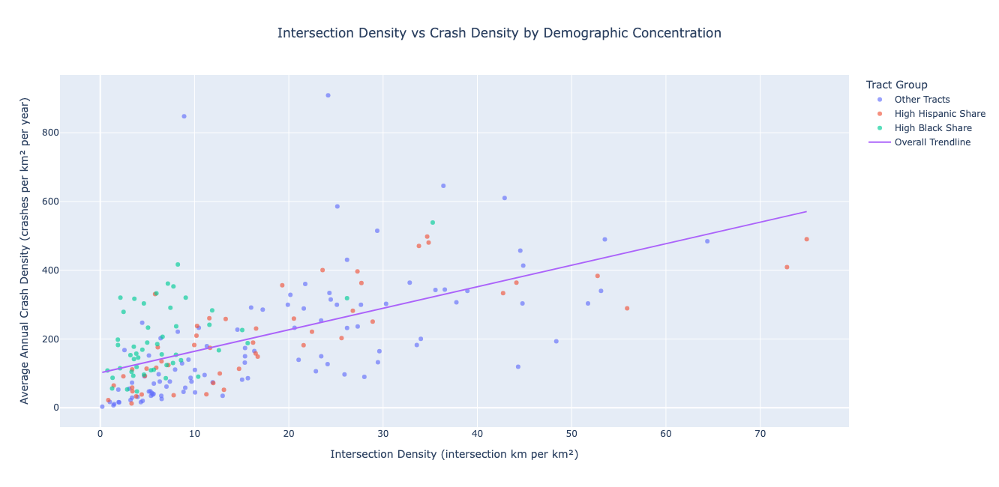

In [25]:
fig = px.scatter(
    tract_eda,
    x="intersection_density_km2",
    y="avg_annual_crash_density",
    color="demo_highlight",
    hover_name="GEOID",
    hover_data=[
        "total_crashes",
        "area_km2",
        "road_density_km_per_km2",
        "avg_annual_crash_density",
        "black_alone_share",
        "white_alone_share",
        "asian_alone_share",
        "hispanic_share",
        "mean_aadt"
    ],
    trendline="ols",
    trendline_scope="overall",
    opacity=0.65,
    title="Road Density vs Crash Density by Demographic Concentration",
    labels={
        "intersection_density_km2": "Intersection Density (intersection km per km²)",
        "avg_annual_crash_density": "Average Annual Crash Density (crashes per km² per year)",
        "demo_highlight": "Tract Group"
    },
    width=1000,
    height=650
)

fig.update_layout(
    title={
        "text": "Intersection Density vs Crash Density by Demographic Concentration",
        "x": 0.5,
        "xanchor": "center"
    }
)

fig.show()

Higher roadway exposure is associated with higher crash density.

Census tracts with higher roadway exposure, such as higher road density, signal density, and intersection density, tend to have higher average annual crash density.

#### 1.11 Black/ Hispanic Share vs. Crash Density

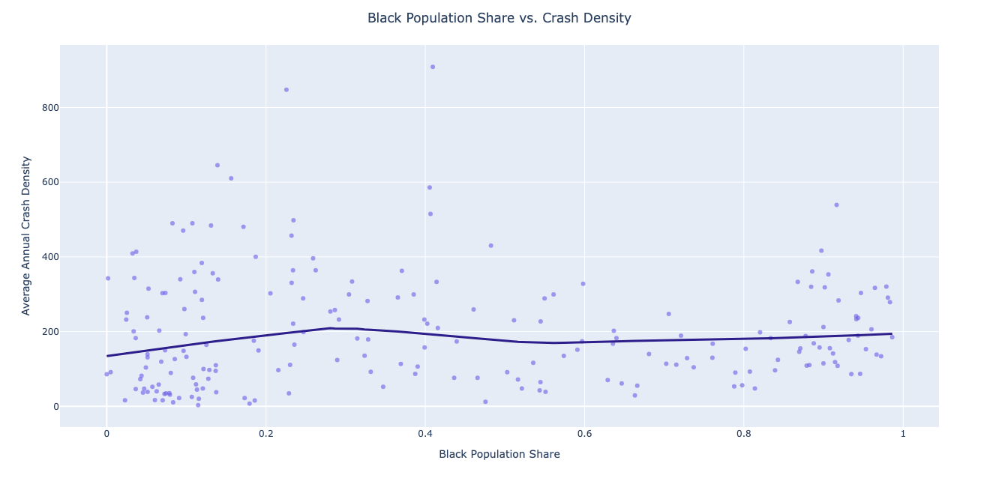

In [45]:
fig = px.scatter(
    tract_eda,
    x="black_alone_share",
    y="avg_annual_crash_density",
    hover_name="GEOID",
    hover_data=[
        "black_alone_share",
        "total_vehicles",
        "area_km2",
        "road_density_km_per_km2",
        "signal_density_km2",
        "intersection_density_km2",
        "mean_aadt"
    ],
    
    trendline="lowess",

    opacity=0.6,

    labels={
        "black_alone_share": "Black Population Share",
        "avg_annual_crash_density": "Average Annual Crash Density",
        "road_density_km_per_km2": "Road Density",
        "signal_density_km2": "Signal Density",
        "intersection_density_km2": "Intersection Density",
        "mean_aadt": "Mean AADT"
    },

    width=1000,
    height=650
)

fig.update_layout(
    title={
        "text": "Black Population Share vs. Crash Density",
        "x": 0.5,
        "xanchor": "center"
    }
)

# Change scatter point color
fig.update_traces(
    marker=dict(color="#6C5CE7"),
    selector=dict(mode="markers")
)

# Change LOWESS trendline color
fig.update_traces(
    line=dict(color="#2D1E8C", width=3),
    selector=dict(mode="lines")
)

fig.show()

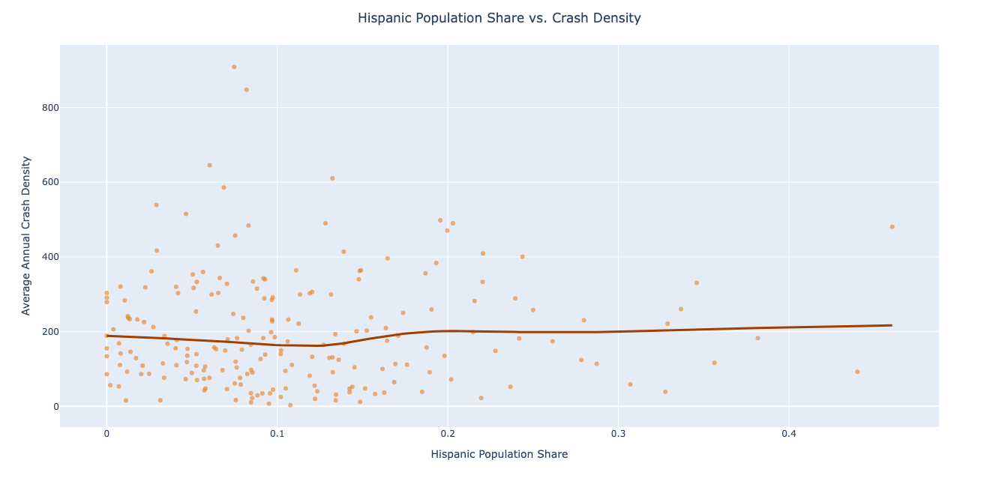

In [43]:
fig = px.scatter(
    tract_eda,
    x="hispanic_share",
    y="avg_annual_crash_density",
    hover_name="GEOID",
    hover_data=[
        "hispanic_share",
        "total_vehicles",
        "area_km2",
        "road_density_km_per_km2",
        "signal_density_km2",
        "intersection_density_km2",
        "mean_aadt"
    ],
    
    trendline="lowess",

    opacity=0.6,

    labels={
        "hispanic_share": "Hispanic Population Share",
        "avg_annual_crash_density": "Average Annual Crash Density",
        "road_density_km_per_km2": "Road Density",
        "signal_density_km2": "Signal Density",
        "intersection_density_km2": "Intersection Density",
        "mean_aadt": "Mean AADT"
    },

    width=1000,
    height=650
)

# Change scatter point color
fig.update_traces(
    marker=dict(color="#E67E22"),
    selector=dict(mode="markers")
)

# Change LOWESS trendline color
fig.update_traces(
    line=dict(color="#A04000", width=3),
    selector=dict(mode="lines")
)

fig.update_layout(
    title={
        "text": "Hispanic Population Share vs. Crash Density",
        "x": 0.5,
        "xanchor": "center"
    }
)

fig.show()

Black and Hispanic population shares alone do not show a strong direct relationship with average annual crash density.

In the roadway exposure scatterplots, high Black-share and high Hispanic-share tracts are highlighted within the broader positive relationship between roadway exposure and crash density. Some high Black-share tracts fall in elevated crash-density areas, but the highest crash-density outliers are not exclusive to high Black-share tracts.

#### 1.12 Boxplot: Black share quartile vs. Hispanic share quartile

In [47]:
# Create quartiles
tract_eda["black_share_q"] = pd.qcut(
    tract_eda["black_alone_share"].rank(method="first"),
    q=4,
    labels=["Q1 Low", "Q2", "Q3", "Q4 High"]
)

tract_eda["hispanic_share_q"] = pd.qcut(
    tract_eda["hispanic_share"].rank(method="first"),
    q=4,
    labels=["Q1 Low", "Q2", "Q3", "Q4 High"]
)

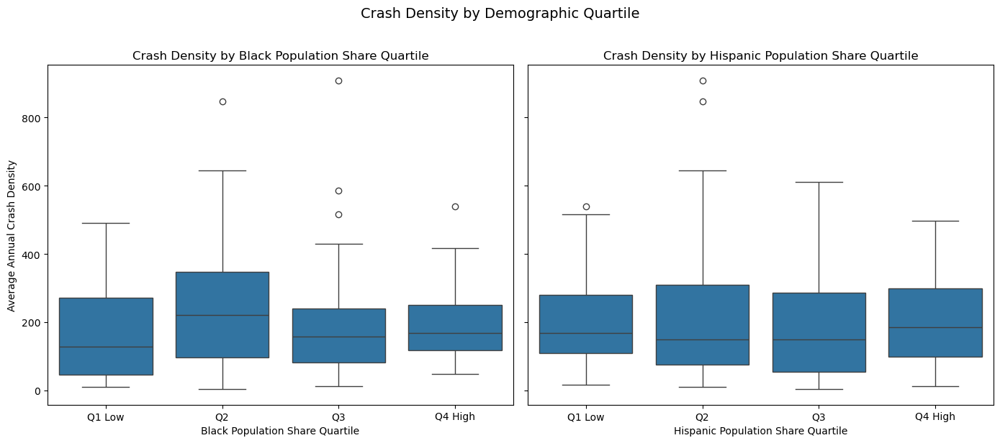

In [48]:
# Plot side-by-side boxplots
fig, axes = plt.subplots(1, 2, figsize=(14,6), sharey=True)

# Black population share
sns.boxplot(
    data=tract_eda,
    x="black_share_q",
    y="avg_annual_crash_density",
    ax=axes[0]
)

axes[0].set_title("Crash Density by Black Population Share Quartile")
axes[0].set_xlabel("Black Population Share Quartile")
axes[0].set_ylabel("Average Annual Crash Density")

# Hispanic population share
sns.boxplot(
    data=tract_eda,
    x="hispanic_share_q",
    y="avg_annual_crash_density",
    ax=axes[1]
)

axes[1].set_title("Crash Density by Hispanic Population Share Quartile")
axes[1].set_xlabel("Hispanic Population Share Quartile")
axes[1].set_ylabel("")

plt.suptitle("Crash Density by Demographic Quartile", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

1. x-axis Q1–Q4 = Black/Hispanic population shared with 4 quantile groups 
- ***Q1 Low*** = Black/Hispanic population share with the last 25% quantile tracts
- ***Q2*** = 25%-50%
- ***Q3*** = 50%-75%
- ***Q4 High*** = Black/Hispanic population share with the top 25% quantile tracts

Q4 High does not mean crash density is in the top 25%. It means the tract belongs to the top 25% of Black or Hispanic population share.

2. The lower and upper edges of each box = the 25th and 75th percentiles of crash density within each group

The boxplot then shows the crash-density distribution within that demographic quartile.